In [46]:
import time
import pandas as pd

In [47]:
#loading the model
CHECKPOINT_DIR = "/home/user/Sync/backup/checkpoints"
model = tf.keras.models.load_model(
    os.path.join(CHECKPOINT_DIR, "mobilenetv2_best.keras")
)

In [48]:
for layer in model.layers:
    print(layer.name)

mri_images
mobilenet_preprocessing
mobilenetv2_1.00_224
global_average_pooling2d
dropout
Classification


In [49]:
#getting the base model last layer
base_model = model.get_layer("mobilenetv2_1.00_224")

In [50]:
base_model.trainable = True

#freeze all layers
for layer in base_model.layers :
    layer.trainable = False

#unfreeze the last 30 layers
for layer in base_model.layers[-30:] :
    layer.trainable = True


In [51]:
#recreating the checkpoint callback

FINETUNING_DIR = "/home/user/Sync/backup/checkpoints"
os.makedirs(FINETUNING_DIR, exist_ok=True)


finetuning_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        FINETUNING_DIR, "mobilenetv2_finetuned_best.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

In [52]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate =0.0001 ),
    loss= 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [53]:
start_time = time.time()

history_finetuning = model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs = 20,
    callbacks = [
        finetuning_checkpoint,
        early_stopping_callback
    ]
)

finetuning_time = time.time() - start_time

print(f"Fine-tuning time: {finetuning_time / 60:.2f} minutes")

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8509 - loss: 0.5360
Epoch 1: val_loss improved from inf to 0.41358, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_finetuned_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - accuracy: 0.8512 - loss: 0.5349 - val_accuracy: 0.9003 - val_loss: 0.4136
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9787 - loss: 0.0550
Epoch 2: val_loss improved from 0.41358 to 0.26566, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_finetuned_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9788 - loss: 0.0549 - val_accuracy: 0.9259 - val_loss: 0.2657
Epoch 3/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9933 - loss: 0.0198
Epoch 3: val_loss improved from 0.26566 to 0.22254, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_finetuned_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9933 - loss: 0.0198 - val_accuracy: 0.943

In [57]:
ARTIFACTS_DIR = "/home/user/Sync/backup/artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

with open(os.path.join(ARTIFACTS_DIR,"fine_tuning_history.json"), "w") as f:
    json.dump(history_finetuning.history, f)

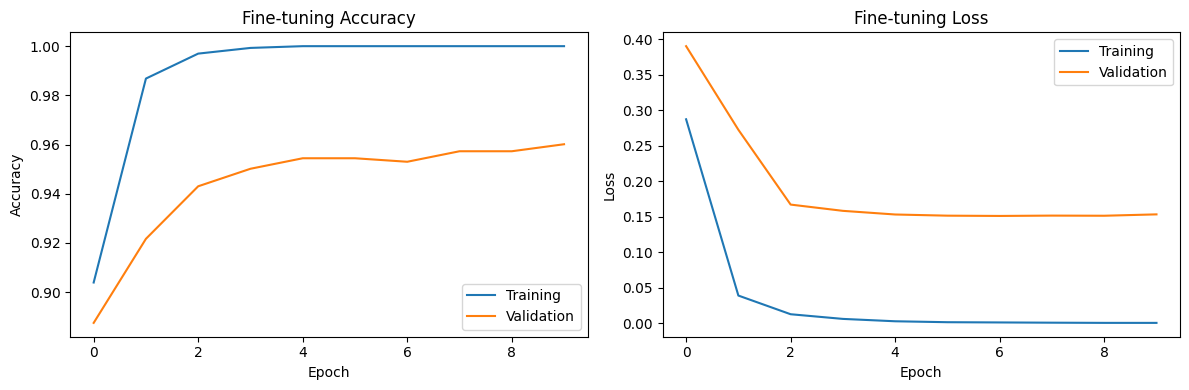

In [79]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_finetuning.history["accuracy"], label="Training")
plt.plot(history_finetuning.history["val_accuracy"], label="Validation")
plt.title("Fine-tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_finetuning.history["loss"], label="Training")
plt.plot(history_finetuning.history["val_loss"], label="Validation")
plt.title("Fine-tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
# camparison tf vs ft

import json

with open(os.path.join(ARTIFACTS_DIR,"transfer_learning_history.json"), "r") as f:
    history_tl_data = json.load(f)

with open(os.path.join(ARTIFACTS_DIR,"fine_tuning_history.json"), "r") as f:
    history_ft_data = json.load(f)

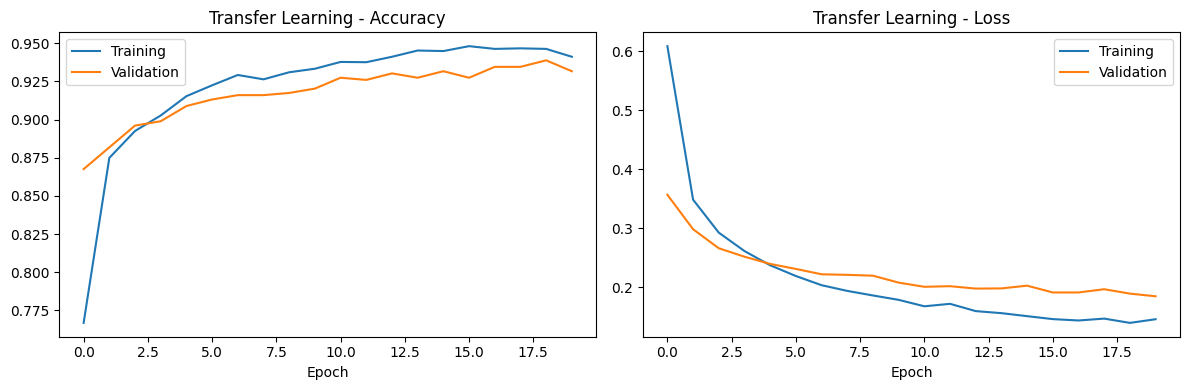

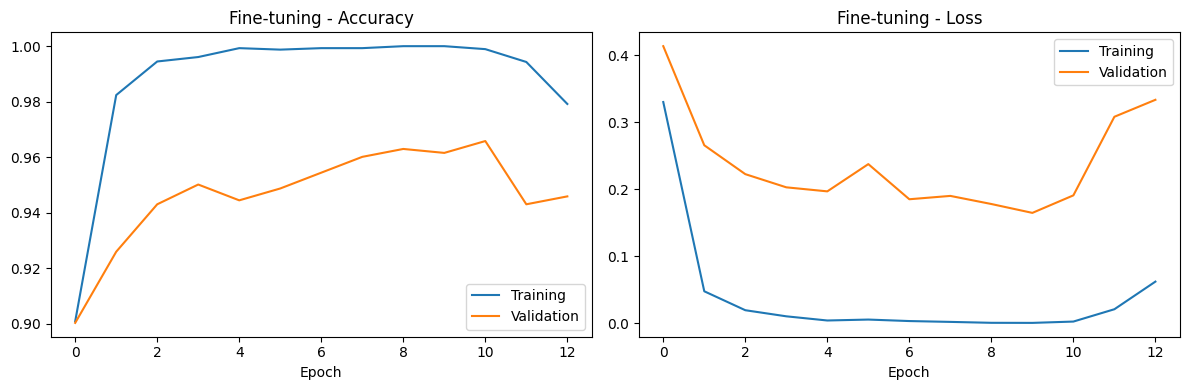

In [59]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):
    plt.figure(figsize=(12, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="Training")
    plt.plot(history["val_accuracy"], label="Validation")
    plt.title(f"{model_name} - Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="Training")
    plt.plot(history["val_loss"], label="Validation")
    plt.title(f"{model_name} - Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history_tl_data, "Transfer Learning")
plot_history(history_ft_data, "Fine-tuning")